In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "8a5255b0fce49fc730baae6ea6ecc601d45bb16b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/8a5255b0fce49fc730baae6ea6ecc601d45bb16b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Backpropagation Through Time

The RNN language model of that section trained only because we
clipped its gradients: without clipping, an occasional enormous gradient
wrecks the parameters. Where do such gradients come from? A recurrent
network applies the same weights at every time step, so a gradient that
travels backward through the sequence is multiplied by a similar factor at
each step. Over many steps these factors compound, the way interest
compounds a deposit, and the gradient grows or shrinks geometrically.

The simplest recurrence shows the effect. Consider a scalar state that
keeps a fraction $w_\textrm{h}$ of its value at each step and adds the new
input, $h_t = w_\textrm{h} h_{t-1} + x_t$. Unrolling it gives $h_t =
\sum_{s \leq t} w_\textrm{h}^{t-s} x_s$, so the derivative of $h_t$ with
respect to the state $k$ steps earlier is $w_\textrm{h}^k$. With
$w_\textrm{h} = 0.9$, forty steps shrink this derivative to $0.9^{40}
\approx 0.015$. With $w_\textrm{h} = 1.1$, they inflate it to $1.1^{40}
\approx 45$, as forty years at 10% interest multiply a deposit 45-fold.
Over long sequences the gradient either fades or blows up.

Both outcomes hurt. A gradient that explodes destabilizes training, which is
why we clipped. A gradient that vanishes is harder to notice and does more
damage. The model receives almost no signal about how a token forty steps
back should have changed its prediction now, because that signal is buried
under the gradients of nearby tokens, so it learns the dependency slowly if
at all.

To compute the gradient of a recurrent network, we unroll the recurrence
over time into a feedforward network whose layers share their weights, and
apply the chain rule. This is called *backpropagation through time*
[@Werbos.1990]. The gradient turns out to be a sum over earlier steps,
and each term carries a product of Jacobians. For a linear recurrence this
product is a matrix power, whose eigenvalues decide whether the gradient
vanishes or explodes. Finally, we bound the cost of backpropagating through
long sequences by truncation and ask what truncation gives up.

In [ ]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

## The Unrolled Computational Graph

We first keep every quantity scalar, which exposes the dependency structure.
The vector case replaces each derivative by a Jacobian. Write $h_t$, $x_t$,
and $o_t \in \mathbb{R}$ for the state, the input, and the output at step
$t$. The state update $g$ has parameter $w_\textrm{h}$ and the output map $f$
has parameter $w_\textrm{o}$, the same at every step:

$$
\begin{aligned}h_t &= g(h_{t-1}, x_t, w_\textrm{h}),\\
o_t &= f(h_t, w_\textrm{o}).\end{aligned}
$$

The objective averages the per-step loss over all $T$ steps,
$L = \frac{1}{T}\sum_{t=1}^T l(y_t, o_t)$.

Unrolling the recurrence turns it into a feedforward network with one layer
per time step, in which every layer uses the same $w_\textrm{h}$.
Backpropagation through this network is ordinary backpropagation with one
rule for shared parameters: the gradient of a parameter that is used in many
places is the sum of its gradients at each place, just as the gradient of a
convolution kernel sums over the positions where the kernel is applied.

The output parameter $w_\textrm{o}$ is easy, since it reaches $L$ only
through each $o_t$ directly. The state parameter $w_\textrm{h}$ is harder:
it affects every state, and every state affects all later ones. By the chain
rule,

$$
\frac{\partial L}{\partial w_\textrm{h}} = \frac{1}{T}\sum_{t=1}^T
\frac{\partial l(y_t, o_t)}{\partial o_t}\,
\frac{\partial f(h_t, w_\textrm{o})}{\partial h_t}\,
\frac{\partial h_t}{\partial w_\textrm{h}}.
$$

The first two factors are local to step $t$. The third is not, because
$h_t$ depends on $w_\textrm{h}$ directly and also through $h_{t-1}$, which
depends on $w_\textrm{h}$ in turn:

$$
\frac{\partial h_t}{\partial w_\textrm{h}} =
\frac{\partial g(h_{t-1}, x_t, w_\textrm{h})}{\partial w_\textrm{h}} +
\frac{\partial g(h_{t-1}, x_t, w_\textrm{h})}{\partial h_{t-1}}\,
\frac{\partial h_{t-1}}{\partial w_\textrm{h}}.
$$

This recursion has the form $a_t = b_t + c_t a_{t-1}$ with $a_0 = 0$, since
the initial state does not depend on $w_\textrm{h}$. Substituting the
recursion into itself $t-1$ times gives, for $t \geq 1$,

$$
a_t = b_t + \sum_{i=1}^{t-1}\Big(\prod_{j=i+1}^{t} c_j\Big) b_i.
$$

Each $b_i$ enters once, multiplied by all the $c_j$ that come after it. With
$a_t = \partial h_t/\partial w_\textrm{h}$,
$b_t = \partial g/\partial w_\textrm{h}$, and
$c_t = \partial g/\partial h_{t-1}$, the recursion
the equation unrolls into

$$
\frac{\partial h_t}{\partial w_\textrm{h}} =
\frac{\partial g(h_{t-1}, x_t, w_\textrm{h})}{\partial w_\textrm{h}} +
\sum_{i=1}^{t-1}\Big(\prod_{j=i+1}^{t}
\frac{\partial g(h_{j-1}, x_j, w_\textrm{h})}{\partial h_{j-1}}\Big)
\frac{\partial g(h_{i-1}, x_i, w_\textrm{h})}{\partial w_\textrm{h}}.
$$

The term for step $i$ is the effect of $w_\textrm{h}$ at that step, carried
forward to step $t$ by the product of the $t-i$ state Jacobians
$\partial g/\partial h_{j-1}$ in between. For the recurrence of the opening,
$g = w_\textrm{h} h_{t-1} + x_t$, every one of these Jacobians equals
$w_\textrm{h}$, and the term from $t-i$ steps back is scaled by
$w_\textrm{h}^{t-i}$. The full sum is exact, but its cost grows with $t$.
Its long products are also where the numbers go wrong, as the vector case
shows.

## Vanishing and Exploding Gradients

In the vector case the product of Jacobians becomes a product of matrices.
Take the RNN of that section and drop the biases and the nonlinearity.
For a minibatch of $b$ examples with inputs $\mathbf{X}_t \in
\mathbb{R}^{b\times d}$, the states and outputs are

$$
\mathbf{H}_t = \mathbf{X}_t \mathbf{W}_\textrm{xh} +
\mathbf{H}_{t-1}\mathbf{W}_\textrm{hh}, \qquad
\mathbf{O}_t = \mathbf{H}_t \mathbf{W}_\textrm{hq},
$$

with $\mathbf{W}_\textrm{xh}\in\mathbb{R}^{d\times h}$,
$\mathbf{W}_\textrm{hh}\in\mathbb{R}^{h\times h}$, and
$\mathbf{W}_\textrm{hq}\in\mathbb{R}^{h\times q}$, as in that section.
the figure draws three steps of this network, with the forward
pass in grey and the backward pass in red.

![Forward pass (grey) and backward pass (red) of a linear RNN unrolled over three time steps. The gradient that reaches each hidden state except the last is the sum of two red arrows: one from its own output, through $\mathbf{W}_\textrm{hq}^\top$, and one from the next state, through $\mathbf{W}_\textrm{hh}^\top$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rnn-bptt.svg)

Write $\mathbf{G}_t = \partial L/\partial \mathbf{H}_t$ for the gradient of
the objective with respect to the state, a matrix of the same shape as
$\mathbf{H}_t$. The state $\mathbf{H}_t$ affects $L$ along two paths, through
its output $\mathbf{O}_t$ and through the next state $\mathbf{H}_{t+1}$.
Backpropagating through a matrix product multiplies the gradient by the
transpose of the weight (that section), so

$$
\mathbf{G}_t = \frac{\partial L}{\partial \mathbf{O}_t}\mathbf{W}_\textrm{hq}^\top +
\mathbf{G}_{t+1}\mathbf{W}_\textrm{hh}^\top, \qquad \mathbf{G}_{T+1} = \mathbf{0}.
$$

These are the two red arrows into each state of the figure. The
recursion runs backward in time, from $\mathbf{G}_T$ to $\mathbf{G}_1$, and
it has the form of the equation with matrices. Unrolled, it reads

$$
\mathbf{G}_t = \sum_{j=t}^{T} \frac{\partial L}{\partial \mathbf{O}_j}\,
\mathbf{W}_\textrm{hq}^\top\big(\mathbf{W}_\textrm{hh}^\top\big)^{j-t}.
$$

The loss at step $j$ reaches the state $k = j - t$ steps earlier through the
$k^\textrm{th}$ power of $\mathbf{W}_\textrm{hh}^\top$. The parameter
gradients add one term per step, each containing $\mathbf{G}_t$:

$$
\frac{\partial L}{\partial \mathbf{W}_\textrm{hh}} = \sum_{t=1}^{T}
\mathbf{H}_{t-1}^\top \mathbf{G}_t, \qquad
\frac{\partial L}{\partial \mathbf{W}_\textrm{xh}} = \sum_{t=1}^{T}
\mathbf{X}_t^\top \mathbf{G}_t.
$$

Whatever happens to $\mathbf{G}_t$ therefore happens to the gradients of the
weights as well.

A matrix power is governed by the eigenvalues of the matrix.
$\mathbf{W}_\textrm{hh}^\top$ has the same eigenvalues as
$\mathbf{W}_\textrm{hh}$; let $\rho$ be the largest of their magnitudes, the
*spectral radius*. Along an eigenvector with eigenvalue $\lambda$, the
$k^\textrm{th}$ power multiplies by $\lambda^k$, which shrinks geometrically
if $|\lambda| < 1$ and grows geometrically if $|\lambda| > 1$. For large $k$
the norm of the power behaves like $\rho^k$. If $\rho < 1$, the contribution
from far ahead vanishes; if $\rho > 1$, it explodes along the eigenvector
of the largest eigenvalue. This is the scalar $w_\textrm{h}^k$ of the
opening, with $\rho$ in the role of $|w_\textrm{h}|$.

We can check this numerically. A symmetric matrix has real eigenvalues and
orthogonal eigenvectors, so its largest singular value equals $\rho$ and the
operator norm of its $k^\textrm{th}$ power is exactly $\rho^k$. We draw a
random symmetric $100 \times 100$ matrix $\mathbf{J}$, rescale it to spectral
radius 0.9, 1.0, and 1.1, and compute $\|\mathbf{J}^k\|$ as the lag $k$
grows.

rho=0.9: ||J^40|| = 0.0148
rho=1.0: ||J^40|| = 1
rho=1.1: ||J^40|| = 45.3


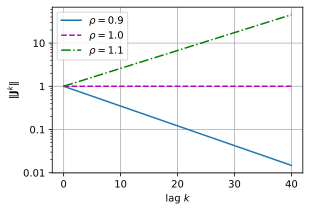

In [2]:
h = 100
M = np.random.default_rng().standard_normal((h, h))
W = (M + M.T) / 2                               # a random symmetric matrix
lags, norms = np.arange(41), []
for rho in (0.9, 1.0, 1.1):
    J = W * (rho / np.abs(np.linalg.eigvalsh(W)).max())  # spectral radius rho
    norms.append([np.linalg.norm(np.linalg.matrix_power(J, k), 2)
                  for k in lags])                # operator norm of J^k
    print(f'rho={rho}: ||J^40|| = {norms[-1][-1]:.3g}')
d2l.plot(lags, norms, xlabel='lag $k$', ylabel=r'$\|\mathbf{J}^k\|$',
         legend=[r'$\rho=0.9$', r'$\rho=1.0$', r'$\rho=1.1$'],
         yscale='log', figsize=(4.5, 3))

On the logarithmic axis the three curves are straight lines: the norm decays
geometrically at $\rho = 0.9$, stays at 1 at $\rho = 1.0$, and grows
geometrically at $\rho = 1.1$. After 40 steps it is $0.9^{40} \approx 0.015$
or $1.1^{40} \approx 45$, the numbers of the opening, whatever the random
matrix. A gradient that has been shrunk to 1.5% or amplified 45-fold carries
little reliable information about a dependency 40 steps back. A general,
nonsymmetric $\mathbf{W}_\textrm{hh}$ can grow for a while even when
$\rho < 1$, but the $\rho^k$ trend wins for large $k$. A nonlinearity such as
the $\tanh$ of that section multiplies each step by its
derivative, a number between 0 and 1 that depends on the state. The
exercises explore what this changes.

### Remedies for Exploding and Vanishing Gradients

The two failure modes need different remedies. For explosion, the immediate
danger is a single update so large that it wrecks the parameters. Gradient
clipping (that section) bounds the step. It replaces the
gradient $\mathbf{g}$ by $\min(1, \theta/\|\mathbf{g}\|)\,\mathbf{g}$
before each update, so no spike can move the parameters far. Training stays
stable while later updates move the recurrence away from the explosive
regime. Clipping does not repair the gradient itself. The gradient is a sum
over lags, as in the equation, and rescaling multiplies
every term by the same factor, so the balance between near and distant lags
is unchanged. For a vanishing gradient that balance is the whole problem.
The terms from distant steps are tiny next to the recent ones, there is no
large step to limit, and no rescaling changes their ratio.

The remedy for vanishing gradients has to change the recurrence itself, so
that the product of Jacobians does not shrink along the directions the model
needs for memory. Two designs do this. *Gated* cells such as the LSTM add a
path along which the state is copied from step to step, scaled by a gate that
the network sets close to 1 when it needs to remember; along this path each
Jacobian is close to the identity. *Linear recurrences* drop the
nonlinearity from the state update and parameterize the state matrix so that
its eigenvalues lie inside the unit circle by construction. Their gradients
cannot explode, and the network can learn eigenvalues close to 1 for the
directions that must remember. Both designs are the subject of
that section.

## Truncated Backpropagation Through Time

Full backpropagation through time also has a cost problem. The backward
recursion the equation needs every state
$\mathbf{H}_1, \ldots, \mathbf{H}_T$ of the forward pass, so memory grows
linearly with the sequence length, and every parameter update requires a
forward and a backward pass over the whole sequence. *The Time Machine* is
about 66,000 BPE tokens long; treated as a single sequence, it would allow
one update per pass through the book, and the backward pass would have to
store all 66,000 states.

*Truncation* bounds both costs. We cut the stream into segments of a fixed
length and backpropagate only within each segment, so that the sum
the equation stops at the end of the segment.
the figure contrasts the two.

![Full and truncated backpropagation through time over a token sequence. Both run the same forward pass (grey). Full backpropagation sends the gradient (red) back along the entire sequence. Truncation cuts the sequence into segments of four tokens and detaches the state at each boundary: its value crosses into the next segment, but no gradient flows back across.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rnn-truncated-bptt.svg)

Truncation drops every term of the equation that crosses a
segment boundary, so the truncated gradient is biased [@Jaeger.2002].
How much is dropped depends on where a loss sits in its segment. The loss at
the last position of a segment of 32 tokens still reaches back 31 steps; the
loss at the first position reaches no earlier state at all. Each loss reaches
back only to the start of its segment: never more than 31 steps, and about
16 on average. This is a hard limit. No gradient ever connects two tokens in
different segments, so the model cannot be trained to use a dependency
longer than a segment, however good its memory path is. The windows of 32
tokens in that section are such segments: every window starts
from a zero state, and every gradient stays inside its window.

When consecutive segments come from one long stream, it helps to carry the
final state of one segment into the next, so that the forward pass still
sees the whole history; only the gradient is cut. Every framework provides an
operation that returns its input unchanged but passes no gradient back, and
applying it to the state at each boundary *detaches* the state from the
computational graph. Without the detach, the graph, and with it the cost of
the backward pass, would grow with every segment processed.

Truncating at a fixed length biases the gradient toward short dependencies.
Truncating at random lengths, and reweighting the surviving terms, gives an
unbiased estimate of the full gradient, but one with a higher variance
[@Tallec.Ollivier.2017]. Fixed-length truncation remains the common
choice.

We can now say where the gradient of a recurrent network comes from, why it
vanishes or explodes, and what truncation removes from it. Clipping handles
explosion. Vanishing gradients remain. Unless the spectral radius of the
recurrence sits close to 1, the signal from a few dozen steps back fades
geometrically, and the gated and linear recurrences described above are
designed to prevent this fading.

## Summary

Backpropagation through time is backpropagation on the unrolled recurrence:
the network becomes a feedforward network with one layer per time step, and
each shared weight sums its gradient over all steps. The gradient that
reaches back $k$ steps carries a product of $k$ state Jacobians, which for a
linear RNN is the $k^\textrm{th}$ power of $\mathbf{W}_\textrm{hh}^\top$ and
scales like $\rho^k$. A spectral radius below 1 makes distant contributions
vanish; one above 1 makes them explode. Clipping controls explosion, while
vanishing requires a change of architecture, such as gating or a linear
recurrence with stable eigenvalues. Truncation bounds the memory and the
compute of the backward pass, but a model trained with it cannot learn
dependencies longer than a segment.

## Exercises

1. **Backward pass by hand.** One step of
   `RNNScratch` (that section) computes
   $$\mathbf{H}_t = \tanh(\mathbf{X}_t \mathbf{W}_{\textrm{xh}} + \mathbf{H}_{t-1} \mathbf{W}_{\textrm{hh}} + \mathbf{b}_\textrm{h}).$$
   Let $\mathbf{G}_t = \partial L / \partial \mathbf{H}_t$ be the gradient
   arriving from later steps and from the output at step $t$.
    1. Derive the contributions of this step to
       $\partial L / \partial \mathbf{W}_{\textrm{xh}}$,
       $\partial L / \partial \mathbf{W}_{\textrm{hh}}$,
       $\partial L / \partial \mathbf{b}_\textrm{h}$, and
       $\partial L / \partial \mathbf{H}_{t-1}$ as functions of
       $\mathbf{G}_t$, $\mathbf{X}_t$, $\mathbf{H}_t$, $\mathbf{H}_{t-1}$,
       and $\mathbf{W}_{\textrm{hh}}$.
    1. Adding the output contribution at step $t-1$ to the contribution
       to $\partial L / \partial \mathbf{H}_{t-1}$ gives a recursion for
       $\mathbf{G}_{t-1}$. Show that it reduces to
       the equation when the $\tanh$ and the bias
       are dropped, and name the factor that the $\tanh$ adds at every step.
       Explain also how the parameter gradients accumulate over the $T$
       steps of a window, and compare with the equation.

    *Adapted from CMU 11-785,
    [Homework 3 Part 1](https://deeplearning.cs.cmu.edu/F22/document/homework/HW3/HW3P1_F22.pdf).*

1. **Power iteration and alignment.** Let
   $\mathbf{M} \in \mathbb{R}^{h \times h}$ be symmetric with eigenvalues
   $\lambda_i$ and eigenvectors $\mathbf{v}_i$ for $i = 1, \ldots, h$,
   ordered so that $|\lambda_i| \geq |\lambda_{i+1}|$.
    1. Show that $\mathbf{M}^k$ has eigenvalues $\lambda_i^k$ with the
       same eigenvectors.
    1. Show that for a random vector $\mathbf{x} \in \mathbb{R}^h$ with
       independent standard normal entries, $\mathbf{M}^k \mathbf{x}$
       becomes aligned with $\mathbf{v}_1$ as $k$ grows. State the
       condition on the eigenvalues that this requires and the sense in
       which the alignment holds.
    1. What does this imply for the gradient the equation
       of an RNN, beyond the change in its norm?

1. **Beyond clipping.** Propose two methods for coping with exploding
   gradients in a plain RNN other than clipping, truncation, and the
   two architectural remedies
   of that section. One method should act on
   the parameters and the other on the optimizer step. For each, state
   whether it changes the product of Jacobians in
   the equation or only limits what a large gradient
   does to the update, and whether it also helps against vanishing
   gradients. If it changes the product, name the property of the
   product that it controls.

1. [code] **Backward pass in code.** ● Train `d2l.RNNLMScratch` on
   `d2l.TimeMachine` as in that section. Using the
   single-step gradients and the recursion of problem 1,
   implement the backward pass of its `RNNScratch` cell over a full
   window with tensor operations only, starting from the gradient of the
   loss with respect to the
   logits (that section). Run it on one training
   minibatch, and compare your gradients of `W_xh`, `W_hh`, and `b_h`
   with those computed by automatic differentiation.

    *Adapted from CMU 11-785,
    [Homework 3 Part 1](https://deeplearning.cs.cmu.edu/F22/document/homework/HW3/HW3P1_F22.pdf).*

1. [code] **Nonlinear Jacobians.** ● Rerun the experiment of
   that section at the same three spectral radii
   with two changes.
    1. Replace the symmetric matrix by a general, nonsymmetric
       $\mathbf{W}_\textrm{hh}$ rescaled to each radius, and plot
       $\|\mathbf{J}^k\|$ against $k$. Report the largest value of
       $\|\mathbf{J}^k\|$ at $\rho = 0.9$ and the lag at which it occurs.
       Explain why the ratio $\|\mathbf{J}^k\| / \rho^k$ can exceed one
       and why it stays bounded as $k$ grows (a random matrix is
       diagonalizable with probability one).
    1. Return to the symmetric $\mathbf{W}_\textrm{hh}$ and run the
       $\tanh$ RNN
       $$\mathbf{H}_t = \tanh(\mathbf{H}_{t-1}\mathbf{W}_\textrm{hh} + \mathbf{X}_t), \qquad \mathbf{H}_0 = \mathbf{0},$$
       for a single sequence ($\mathbf{H}_t \in \mathbb{R}^{1 \times h}$)
       with inputs $\mathbf{X}_t$ whose entries are drawn independently
       from $\mathcal{N}(0, s^2)$.
       Plot the norm of the product of the Jacobians
       $\partial \mathbf{H}_j / \partial \mathbf{H}_{j-1}$ along the
       trajectory for $s = 0.1$ and $s = 1$. How do the nonlinearity and
       the input scale change the growth of the norm, and why?
    1. Explain why a largest singular value of $\mathbf{W}_\textrm{hh}$
       below one is sufficient for the product to shrink, whereas a
       largest singular value above one is necessary but not sufficient
       for it to grow [@bengio1994learning; @Pascanu.Mikolov.Bengio.2013].
       Relate the argument to your $\tanh$ curves at $\rho = 0.9$ and
       $\rho = 1.1$.

1. [code] **Effective memory horizon.** ● Take the RNN language model
   trained in that section and a fixed input sequence of
   several hundred tokens. Measure the norm of the gradient of the loss
   at the final step with respect to the hidden state $k$ steps earlier,
   as a function of $k$, and plot it.
    1. Read off the lag beyond which the norm drops below one percent of
       its value at $k = 0$.
    1. Compare this horizon with the window length `num_steps` used in
       training. Which of the two, the truncation at `num_steps` or the
       decay of the gradient, limits the longest dependency the model
       could have learned?
    1. Retrain with `num_steps` set to 128, measure the horizon again,
       and explain the change or its absence in terms of the product of
       state Jacobians in the equation.

[Discussions](https://d2l.discourse.group/t/334)